# Optimism enhances cooperation in a social coordination task
In this section, we investigate the impact of optimism/pessimism on the stag-hunt game defined in Section @sec-environments. This is a coordination game between two agents: if both agents cooperate at the same time, they reap the most rewards. First, we import what we need:

In [1]:
# general imports

import numpy as np
from scipy.stats import norm

import jax.numpy as jnp
from jax import jit
from functools import partial

import matplotlib.pyplot as plt
import matplotlib as mpl

import pandas as pd
import seaborn as sns

In [2]:
# pyCRLD imports

# Agents
from pyCRLD.Agents.Base import abase
from pyCRLD.Agents.StrategySARSA import stratSARSA

# Environment
from pyDDRL.Environments.SocialDilemma import SocialDilemma

# Utilities
from pyCRLD.Utils.Helpers import *
from pyDDRL.Utils.Trajectories1D import trajectories_1D 
from pyDDRL.Utils.PhasePlot import phaseplot, _data_to_plot, _strategies, _dXisa_s
from pyDDRL.Utils.PlottingTools import *

In [3]:
# DDRL imports

from pyDDRL.Agents.DDRLBase import DDRLBase
from pyDDRL.Agents.DDRLSarsa import DDRLSarsa

Then, we define the environment:

In [4]:
env = SocialDilemma(R=3, P=0, S=-2, T=1)

## Sanity tests

We carry out sanity tests in order to check that the behavior of neutral DDRLSarsa agents imitate the behavior of regular SARSA agents. Once again, we compare the "mean", "expectile", and "weights" methods. 

In [5]:
# Methods
methods = ["mean", "expectile", "weights"]

# Define agents to compare
aeis_ddrl = [] # DDRLSarsa agents
aeis_reg = []  # regular SARSA agents

for i, method in enumerate(methods):
    aei_ddrl = DDRLSarsa(env, nr_reward_bins=29, discretization_sigma=0.08, 
                        learning_rates=0.1, discount_factors=0.9, 
                        choice_intensities=50, Rmin=-2, Rmax=3,
                        method=method, use_prefactor=True)
    aeis_ddrl.append(aei_ddrl)
    
    aei_reg = stratSARSA(env=env, learning_rates=0.1, discount_factors=0.9, 
                         choice_intensities=50, use_prefactor=True)
    aeis_reg.append(aei_reg)

Additionally, we plot trajectories with various initial conditions for better visualization.

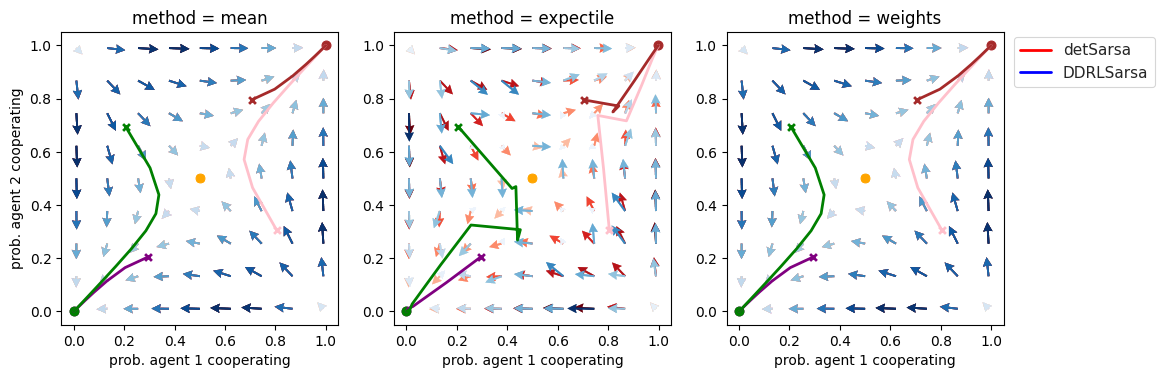

In [6]:
# Phase space items to plot along the axes
x = ([0], [0], [0])  # agent 1
y = ([1], [0], [0])  # agent 2

# For trajectories
Xinits = []
xys = [(0.5, 0.5), (0.295, 0.205), (0.205, 0.695), (0.805, 0.305), (0.705, 0.795)]
cols = ['orange', 'purple', 'green', 'pink', 'brown']
        
for t, xy in enumerate(xys):
    Xinit = np.ones((2, 1, 2)) * 0.5
    Xinit[0, 0, 0] = xy[0]
    Xinit[1, 0, 0] = xy[1]
    Xinit[0, 0, 1] = 1 - Xinit[0, 0, 0]
    Xinit[1, 0, 1] = 1 - Xinit[1, 0, 0]
    Xinits.append(Xinit)

# Decorations
titles = ["method = mean", "method = expectile", "method = weights"]
xlabel = "prob. agent 1 cooperating"
ylabel = "prob. agent 2 cooperating"

# Figure and axes
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(3.2 * 3.8, 3.8))
axes = [ax1, ax2, ax3]

# Plot flow plots and trajectories
plot_3flowplots(aeis_reg, x, y, NrRandom=16, cmap='Reds', axes=axes)
plot_3flowplots(aeis_ddrl, x, y, NrRandom=16, cmap='Blues', decorate=True,
                titles=titles, xlabel=xlabel, ylabel=ylabel,
                Xinits=Xinits, cols=cols, axes=axes)

# Additional decorations
ax3.plot([], [], color='red', label='detSarsa')
ax3.plot([], [], color='blue', label='DDRLSarsa')
ax3.legend(bbox_to_anchor=(1.01, 1.01))

# Save the figure
plt.savefig('../figs/SHSanityTests.png', dpi=300, bbox_inches='tight')